In [ ]:
!pip install -q transformers

from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/lane_work

!cp /content/drive/MyDrive/driving-perception/lane_frames.zip /content/lane_work/

!unzip -q -o /content/lane_work/lane_frames.zip -d /content/lane_work/

!ls /content/lane_work/results/lanes/frames | wc -l

Mounted at /content/drive
40


preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

class 0 is: road


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

model.safetensors: downloading bytes:           |  0.00B            

{
  "frames": 20,
  "frames_with_classical_line": 20,
  "mean_line_pixels_on_road_pct": 99.8,
  "model": "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
  "note": "Sanity check only. The segmentation model was not trained by me and has no lane-marking class. A classical line can lie on 'road' and still be on the wrong lane. No ground-truth lane labels were used."
}


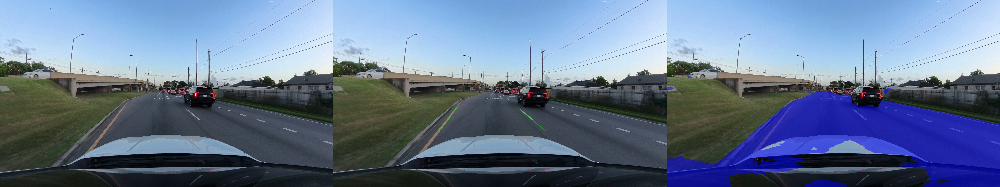

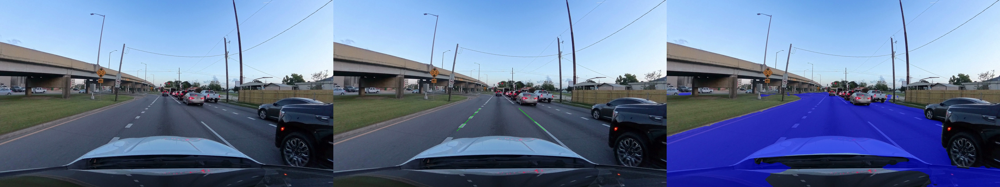

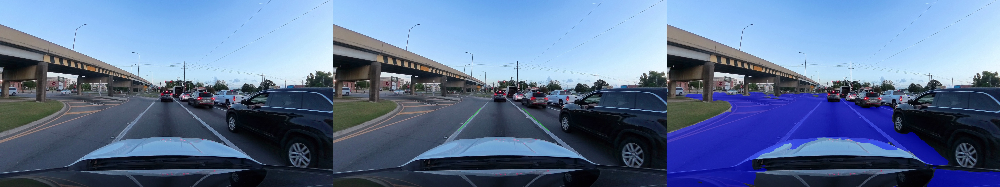

In [ ]:
import glob, os, json
import numpy as np, cv2, torch
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation

FRAMES = "/content/lane_work/results/lanes/frames"
OUT = "/content/drive/MyDrive/driving-perception/lane_comparison"
os.makedirs(OUT, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)
model = SegformerForSemanticSegmentation.from_pretrained(name).to(device).eval()
ROAD_ID = 0
print("class", ROAD_ID, "is:", model.config.id2label[ROAD_ID])


@torch.no_grad()
def road_mask(bgr):
  """True where the model predicts 'road'."""
  rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
  inputs = processor(images=rgb, return_tensors="pt").to(device)
  logits = model(**inputs).logits
  logits = torch.nn.functional.interpolate(logits, size=bgr.shape[:2], mode="bilinear", align_corners=False)
  return (logits.argmax(dim=1)[0] == ROAD_ID).cpu().numpy()

rows = []
for orig_path in sorted(glob.glob(f"{FRAMES}/*_original.jpg")):
  stem = os.path.basename(orig_path).replace("_original.jpg", "")
  orig = cv2.imread(orig_path)
  classical = cv2.imread(orig_path.replace("_original", "_classical"))
  if orig is None or classical is None:
    print("skipping", stem)
    continue

  road = road_mask(orig)
  # pixels where the classical overlay differs from the original = drawn lane lines
  drawn = np.abs(classical.astype(int) - orig.astype(int)).sum(axis=2) > 90
  n_line = int(drawn.sum())
  on_road = (drawn & road).sum() / n_line * 100 if n_line else None

  seg_vis = orig.copy()
  seg_vis[road] = (0.5 * seg_vis[road] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
  panel = np.hstack([orig, classical, seg_vis])
  panel = cv2.resize(panel, None, fx=0.5, fy=0.5)
  cv2.imwrite(f"{OUT}/{stem}_comparison.jpg", panel)

  rows.append({
      "frame": stem,
      "classical_line_pixels": n_line,
      "road_pct_of_frame": round(float(road.mean() * 100), 1),
      "line_pixels_on_road_pct": None if on_road is None else round(float(on_road), 1),
       })
valid = [r["line_pixels_on_road_pct"] for r in rows if r["line_pixels_on_road_pct"] is not None]
summary = {
      "frames": len(rows),
      "frames_with_classical_line": len(valid),
      "mean_line_pixels_on_road_pct": round(float(np.mean(valid)), 1) if valid else None,
      "model": name,
      "note": ("Sanity check only. The segmentation model was not trained by me and has no "
               "lane-marking class. A classical line can lie on 'road' and still be on the wrong "
               "lane. No ground-truth lane labels were used."),
  }
with open(f"{OUT}/segmentation_summary.json", "w") as f:
  json.dump({"summary": summary, "frames": rows}, f, indent=2)

print(json.dumps(summary, indent=2))

from google.colab.patches import cv2_imshow
for p in sorted(glob.glob(f"{OUT}/*_comparison.jpg"))[:3]:
  cv2_imshow(cv2.imread(p))
